In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

RANDOM_STATE = 42
TARGET_COLUMN = "Machine failure"
DECISION_THRESHOLD = 0.25

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
cwd = Path.cwd()

PROJECT_ROOT = next(
    (
        path
        for path in [cwd, *cwd.parents]
        if (path / "data" / "raw" / "ai4i2020.csv").exists()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find data/raw/ai4i2020.csv. "
        "Check your notebook's working directory."
    )

df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ai4i2020.csv")

print("Dataset shape:", df.shape)
print("Project root:", PROJECT_ROOT)

Dataset shape: (10000, 14)
Project root: d:\robotic-predictive-maintenance


In [3]:
NUMERICAL_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

CATEGORICAL_FEATURES = ["Type"]
FEATURE_COLUMNS = NUMERICAL_FEATURES + CATEGORICAL_FEATURES

X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

assert X_train.index.intersection(X_test.index).empty

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))
print("Training failures:", int(y_train.sum()))
print("Test failures:", int(y_test.sum()))
print("Test failure rate:", round(y_test.mean() * 100, 2), "%")

Training observations: 8000
Test observations: 2000
Training failures: 271
Test failures: 68
Test failure rate: 3.4 %


In [4]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, NUMERICAL_FEATURES),
    ("cat", categorical_pipeline, CATEGORICAL_FEATURES)
])

final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

print("Final model pipeline configured.")

Final model pipeline configured.


In [5]:
final_model.fit(X_train, y_train)

print("Model fitted successfully.")
print("Training observations used:", len(X_train))

Model fitted successfully.
Training observations used: 8000


In [6]:
test_probabilities = final_model.predict_proba(X_test)[:, 1]

test_predictions = (
    test_probabilities >= DECISION_THRESHOLD
).astype(int)

print("Test probabilities generated.")
print("Decision threshold:", DECISION_THRESHOLD)
print("Predicted failures:", int(test_predictions.sum()))
print("Actual failures:", int(y_test.sum()))

Test probabilities generated.
Decision threshold: 0.25
Predicted failures: 136
Actual failures: 68


In [7]:
tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
).ravel()

test_metrics = {
    "model": "Hist_Gradient_Boosting",
    "decision_threshold": DECISION_THRESHOLD,
    "accuracy": accuracy_score(y_test, test_predictions),
    "average_precision": average_precision_score(
        y_test, test_probabilities
    ),
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "precision": precision_score(
        y_test, test_predictions, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_predictions, zero_division=0
    ),
    "f1": f1_score(
        y_test, test_predictions, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_predictions
    ),
    "true_positives": int(tp),
    "false_positives": int(fp),
    "true_negatives": int(tn),
    "false_negatives": int(fn),
    "false_alarms_per_1000": fp / len(y_test) * 1000
}

test_metrics_df = pd.DataFrame([test_metrics])
test_metrics_df.T

,0
model,Hist_Gradient_Boosting
decision_threshold,0.25
accuracy,0.957
average_precision,0.824608
roc_auc,0.974425
precision,0.433824
recall,0.867647
f1,0.578431
balanced_accuracy,0.913896
true_positives,59


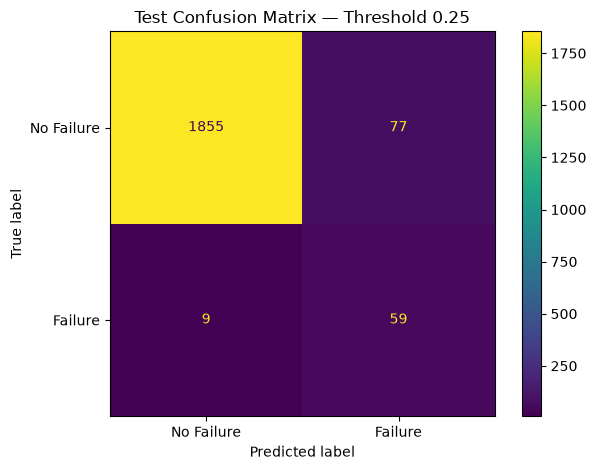

In [8]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

disp.plot(values_format="d")
plt.title(f"Test Confusion Matrix — Threshold {DECISION_THRESHOLD}")
plt.tight_layout()
plt.show()

In [9]:
print(
    classification_report(
        y_test,
        test_predictions,
        labels=[0, 1],
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

  No Failure       1.00      0.96      0.98      1932
     Failure       0.43      0.87      0.58        68

    accuracy                           0.96      2000
   macro avg       0.71      0.91      0.78      2000
weighted avg       0.98      0.96      0.96      2000



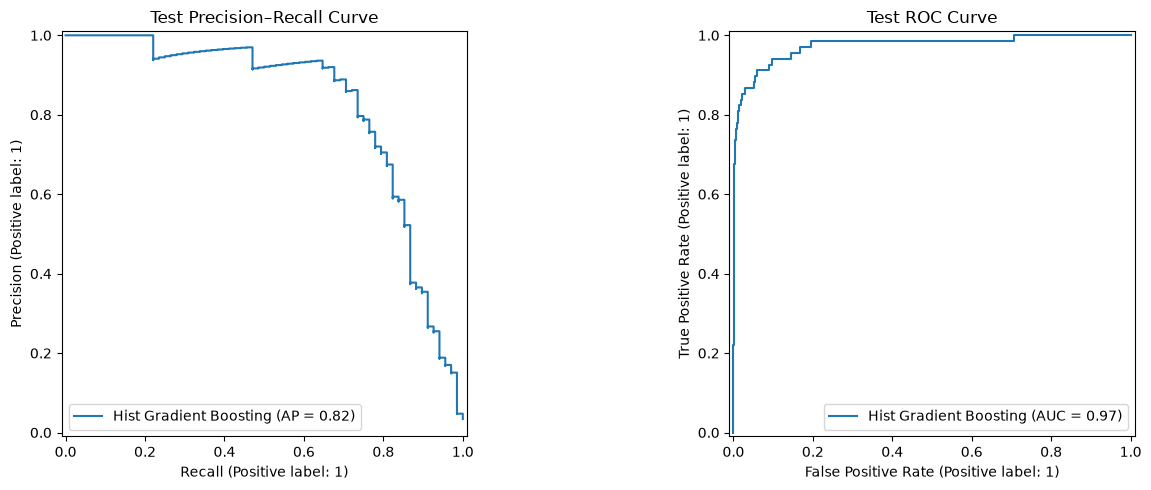

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Hist Gradient Boosting",
    ax=axes[0]
)
axes[0].set_title("Test Precision–Recall Curve")

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities,
    name="Hist Gradient Boosting",
    ax=axes[1]
)
axes[1].set_title("Test ROC Curve")

plt.tight_layout()
plt.show()

In [11]:
METRICS_DIR = PROJECT_ROOT / "artifacts" / "metrics"
REPORTS_DIR = PROJECT_ROOT / "artifacts" / "reports"
PLOTS_DIR = PROJECT_ROOT / "artifacts" / "plots"
MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"

for folder in [METRICS_DIR, REPORTS_DIR, PLOTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

test_metrics_df.to_csv(
    METRICS_DIR / "final_test_metrics.csv",
    index=False
)

predictions_df = pd.DataFrame({
    "original_index": X_test.index,
    "actual_failure": y_test.to_numpy(),
    "failure_probability": test_probabilities,
    "predicted_failure": test_predictions,
    "decision_threshold": DECISION_THRESHOLD
})

predictions_df.to_csv(
    METRICS_DIR / "final_test_predictions.csv",
    index=False
)

with open(REPORTS_DIR / "final_evaluation_summary.json", "w") as f:
    json.dump(test_metrics, f, indent=4)

print("Saved test metrics, predictions, and evaluation summary.")

Saved test metrics, predictions, and evaluation summary.


In [12]:
import joblib
import json

MODELS_DIR = PROJECT_ROOT / "artifacts" / "models"
REPORTS_DIR = PROJECT_ROOT / "artifacts" / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "final_model_pipeline.joblib"

# Save the complete fitted preprocessing + model pipeline
joblib.dump(final_model, MODEL_PATH)

# Save the decision threshold separately as metadata
model_metadata = {
    "model_name": "Hist_Gradient_Boosting",
    "decision_threshold": 0.25,
    "target_column": "Machine failure",
    "positive_class": 1,
    "negative_class": 0,
    "feature_columns": FEATURE_COLUMNS,
    "numerical_features": NUMERICAL_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "imbalance_strategy": "class_weight_balanced",
    "threshold_selection": (
        "Training out-of-fold predictions; maximize precision "
        "among tested thresholds with recall >= 0.85"
    ),
    "test_set_used_for_threshold_selection": False
}

METADATA_PATH = REPORTS_DIR / "final_model_metadata.json"

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=4)

print("Model saved:", MODEL_PATH)
print("Metadata saved:", METADATA_PATH)

Model saved: d:\robotic-predictive-maintenance\artifacts\models\final_model_pipeline.joblib
Metadata saved: d:\robotic-predictive-maintenance\artifacts\reports\final_model_metadata.json


In [13]:
import joblib
import numpy as np

loaded_model = joblib.load(MODEL_PATH)

# Predict probabilities on a few test observations
sample_X = X_test.iloc[:5]
sample_probabilities = loaded_model.predict_proba(sample_X)[:, 1]

sample_predictions = (
    sample_probabilities >= 0.25
).astype(int)

verification_df = pd.DataFrame({
    "actual_failure": y_test.iloc[:5].to_numpy(),
    "failure_probability": sample_probabilities,
    "predicted_failure": sample_predictions
})

display(verification_df)

assert np.isfinite(sample_probabilities).all()
assert len(sample_probabilities) == 5

print("Saved model loaded and prediction check passed.")

,actual_failure,failure_probability,predicted_failure
0,0,0.402347,1
1,0,0.000695,0
2,0,0.399173,1
3,0,0.001790,0
4,0,0.072709,0


Saved model loaded and prediction check passed.
